In [1]:
# -*- coding: utf-8 -*-
"""
Created on Sun Oct 18 13:58:33 2020

@author: Liat Colmenares V
Referencia: http://www.fimee.ugto.mx/profesores/ljavier/documentos/Lec01%20-%20Teorema%20de%20Muestreo.pdf
"""


from pylab import *
from scipy.fftpack import fft, fftfreq

In [ ]:
print("ingresa las variables") #Pide todas las variables desde consola para evitar moverle al codigo
A = 1 # float(input("Amplitud: "))
T2  = float(input("Tiempo de Relajación: "))
w = float(input("Desplazamiento Quimico: "))
J = float(input("Constante de Acoplamiento: "))
tmin = 0 #los tiempos negativos no nos sirven de nada
tmax = float(input("Máximo Valor de x: ")) #si le pones menos de 100 sale con poca resolucion la transformada
Np = 2 ** 13 #numero de puntos para la simulacion

In [39]:
A = 1 # float(input("Amplitud: "))
T2  = float(1)
w = float(2)
J = float(0)
tmin = 0 #los tiempos negativos no nos sirven de nada
tmax = float(10) #si le pones menos de 100 sale con poca resolucion la transformada
Np = 2 ** 13 

sw = 50
w2 = w *Np/sw

In [40]:
#Multiplete en el tiempo/ me quise lucir poniendo una función 
def multiplete(t):
#     doblete = A * exp(-t*T2) * cos( 2* pi * w * t) * cos(2 * pi * J * t)
    doblete = A * exp(-t*T2) * cos( 2* pi * w2 * t) * cos(2 * pi * J * t)
    return doblete 

Hacer un cociente que relacione la ventana espectral y el tiempo.

In [41]:
# t = arange(tmin, tmax, (tmax - tmin)/sw) #variable independiente de la función abajo cuando uso el return
t = arange(tmin, tmax, (tmax - tmin)/Np) #variable independiente de la función abajo cuando uso el return
multiplete(t) #llamo a la funcion para usar sus valores mas abajo y no marque error

array([ 1.00000000e+00, -8.08030027e-01,  3.08263479e-01, ...,
       -3.68640681e-05,  4.55109048e-05, -3.67741777e-05])

En la línea anterior la función multiplete no se le está asignando a alguna variable. 

Text(0, 0.5, 'multiplete (t)')

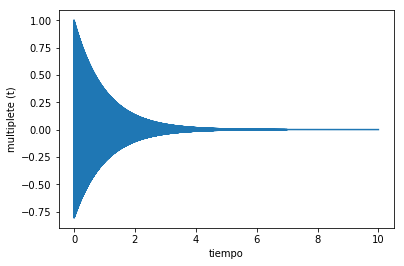

In [42]:
#Grafica multiplete/ una simple grafica 
figure(1)
plot(t, multiplete(t))
xlabel("tiempo")
ylabel("multiplete (t)")

In [43]:
#Transformada de Fourier/ me quise lucir x2 con la función
def transformada():
    x = fft(multiplete(t)) / Np #aplico la transformada al multiplete en el tiempo y normalizo entre el no. de puntos
    x1 = fftshift(x) #ajusto la transformada al cero 
    return x1

In [44]:
transformada() #vuelvo a llamar a la funcion para que no me marque error y usar sus valores

Ts = t[2] - t[1] #Tasa de muestreo: intervalo de tiempo entre 2 muestras
Fs = 1 / Ts #Frecuencia de muestreo: muestras tomadas por segundo
frecuencia = arange(-Fs / 2, Fs / 2, Fs / Np) #variable x de frecuencias para la transformada
print("Para Corroborar: ", len(transformada()), len(frecuencia), Fs/2) #ver comentario de abajo

Para Corroborar:  8192 8192 409.6



1) para la variable de frecuencia se puede hacer tambien con el comando fftfreq 

2) en la linea 48 imprimo el largo del array de transformada y de freccuencia para ver que tengan el mismo no. de puntos por que si no no encajan y no sale la grafica

3) imrpimir Fs/2 nos dice cuanto esmamos viendo en x (corroborar que el numero coincida con los limites de la grafica de fft) y el teorema de muestreo dice que solo se puede ver la mitad de la frecuencia de muestreo 
 

Gracias por Utilizar el Simulador de Liat n.n/



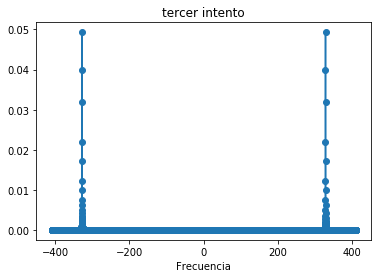

In [45]:
   
#Grafica Transformada de Fourier/ una simple grafica x2
figure(2)
plot(frecuencia, transformada(), marker="o")
# xlim(-20, 20)
title("tercer intento")
xlabel("Frecuencia")

print("Gracias por Utilizar el Simulador de Liat n.n/")
print()

Pensarlo al revés, a partir de definir un cierto dominio de la frecuencia donde se aplicó la transf. de Fourier, pensar como definir el tiempo.

Definir el intervalo en el dominio de la frecuencia. Porque este dominio depende de ``tmax``.

Combinación del número de puntos y de como se normaliza el tiempo.

Redefine w.
$$w = 2\pi * np / sw$$